In [34]:
import pandas as pd
from sklearn.datasets import load_iris
from matplotlib import pyplot as plt
%matplotlib inline

iris = load_iris()

In [35]:
dir(iris)

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [36]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)

In [37]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [38]:
df.drop(["sepal length (cm)", "sepal width (cm)"], axis=1, inplace=True)

In [39]:
df.head()

,petal length (cm),petal width (cm)
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


In [40]:
df["target"] = iris.target

In [41]:
df.head()

,petal length (cm),petal width (cm),target
0,1.4,0.2,0
1,1.4,0.2,0
2,1.3,0.2,0
3,1.5,0.2,0
4,1.4,0.2,0


In [42]:
df0 = df[df["target"] == 0]
df1 = df[df["target"] == 1]
df2 = df[df["target"] == 2]

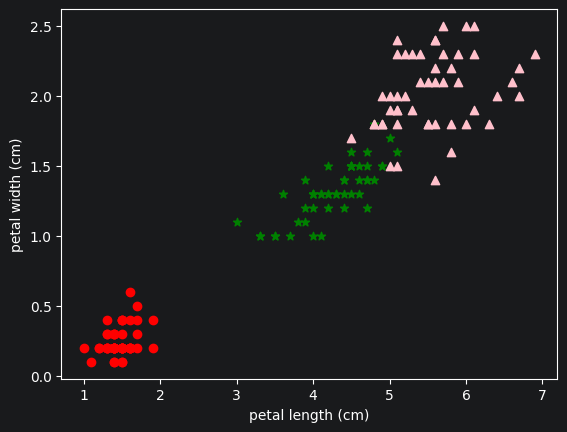

In [51]:
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.scatter(df0["petal length (cm)"], df0["petal width (cm)"], marker="o", color="red")
plt.scatter(df1["petal length (cm)"], df1["petal width (cm)"], marker="*", color="green")
plt.scatter(df2["petal length (cm)"], df2["petal width (cm)"], marker="^", color="pink")

In [44]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3)
km

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [45]:
y_predicted = km.fit_predict(df[["petal length (cm)", "petal width (cm)"]])

In [46]:
y_predicted

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [47]:
df["cluster"] = y_predicted

In [48]:
df.head()

,petal length (cm),petal width (cm),target,cluster
0,1.4,0.2,0,0
1,1.4,0.2,0,0
2,1.3,0.2,0,0
3,1.5,0.2,0,0
4,1.4,0.2,0,0


In [49]:
km.cluster_centers_

array([[1.462     , 0.246     ],
       [5.59583333, 2.0375    ],
       [4.26923077, 1.34230769]])

In [50]:
df_km0 = df[df.cluster == 0]
df_km1 = df[df.cluster == 1]
df_km2 = df[df.cluster == 2]

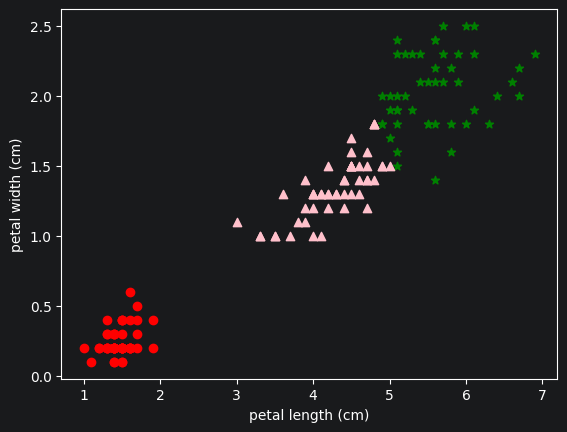

In [52]:
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.scatter(df_km0["petal length (cm)"], df_km0["petal width (cm)"], marker="o", color="red")
plt.scatter(df_km1["petal length (cm)"], df_km1["petal width (cm)"], marker="*", color="green")
plt.scatter(df_km2["petal length (cm)"], df_km2["petal width (cm)"], marker="^", color="pink")

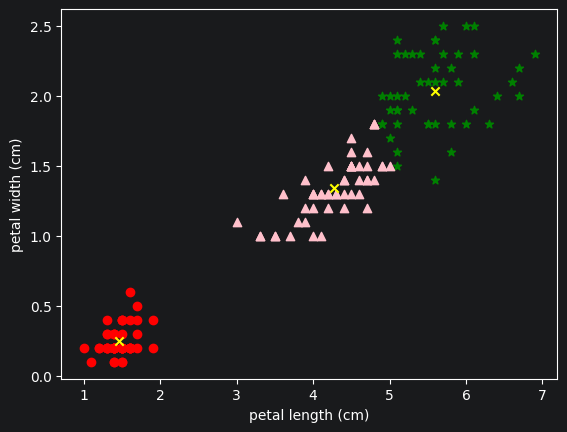

In [53]:
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.scatter(df_km0["petal length (cm)"], df_km0["petal width (cm)"], marker="o", color="red")
plt.scatter(df_km1["petal length (cm)"], df_km1["petal width (cm)"], marker="*", color="green")
plt.scatter(df_km2["petal length (cm)"], df_km2["petal width (cm)"], marker="^", color="pink")
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], marker="x", color="yellow")

In [54]:
# Elbow plt
k_rng = range(1, 10)
sse = []
for k in k_rng:
    km = KMeans(n_clusters=k)
    km.fit(df[["petal length (cm)", "petal width (cm)"]])
    sse.append(km.inertia_)
sse

[550.8953333333334,
 86.39021984551395,
 31.371358974358984,
 19.465989010989013,
 14.701112010796223,
 13.3538477603161,
 9.828416794834645,
 8.77840281940282,
 6.456494541406307]

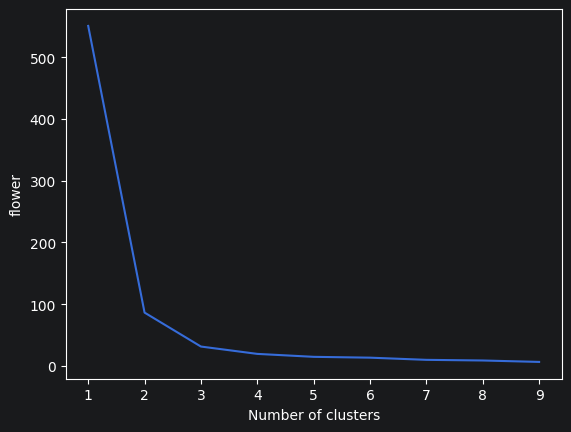

In [56]:
plt.xlabel("Number of clusters")
plt.ylabel("flower")
plt.plot(k_rng, sse)